In [1]:
from Utils.Utils import load_covertype_data

X, y = load_covertype_data()

print("X shape:", X.shape)
print("y shape:", y.shape)

Loading local dataset from 'c:\Users\julia\Desktop\Academics\CENTRALE 3A\CE\DAML\DAML-Forest-Cover-Type-Classification\DATA\raw'
Filtering the dataset based on active features...
X shape: (581012, 54)
y shape: (581012, 1)


In [ ]:
from Utils.Utils import (
    PreprocessingConfig,
    build_preprocessor
)
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

config = PreprocessingConfig(
    scaling=False,
    pca="none"
)


model = RandomForestClassifier(
    n_estimators=20,       # Start with 20 trees instead of 100
    max_depth=15,          # Limit how deep each tree can grow
    min_samples_leaf=5,    # Require at least 5 samples per leaf
    random_state=42,
    n_jobs=1               # Use one CPU worker to reduce memory pressure
)


In [3]:

from Utils.Utils import load_covertype_data, split_data

X, y = load_covertype_data()

X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)


Loading local dataset from 'c:\Users\julia\Desktop\Academics\CENTRALE 3A\CE\DAML\DAML-Forest-Cover-Type-Classification\DATA\raw'
Filtering the dataset based on active features...
Training set: (406708, 54)
Validation set: (87152, 54)
Test set: (87152, 54)


In [4]:

model.fit(X_train, y_train.squeeze())

predictions = model.predict(X_val)

print("Training complete!")
print("Predictions:", predictions.shape)


Training complete!
Predictions: (87152,)


In [5]:

from sklearn.metrics import accuracy_score, classification_report

y_val_true = y_val.squeeze()

accuracy = accuracy_score(y_val_true, predictions)

print(f"Validation accuracy: {accuracy:.4f}")
print(f"Validation accuracy: {accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(y_val_true, predictions))


Validation accuracy: 0.8214
Validation accuracy: 82.14%

Classification report:
              precision    recall  f1-score   support

           1       0.83      0.78      0.80     31776
           2       0.80      0.89      0.85     42495
           3       0.84      0.89      0.86      5363
           4       0.89      0.70      0.78       412
           5       0.95      0.17      0.30      1424
           6       0.89      0.52      0.65      2605
           7       0.95      0.74      0.83      3077

    accuracy                           0.82     87152
   macro avg       0.88      0.67      0.72     87152
weighted avg       0.83      0.82      0.82     87152



In [6]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

balanced_model = RandomForestClassifier(
    n_estimators=20,
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=1
)

balanced_model.fit(X_train, y_train.squeeze())

balanced_predictions = balanced_model.predict(X_val)

print(f"Validation accuracy: {accuracy_score(y_val.squeeze(), balanced_predictions):.2%}")
print(classification_report(y_val.squeeze(), balanced_predictions))


Validation accuracy: 78.60%
              precision    recall  f1-score   support

           1       0.80      0.82      0.81     31776
           2       0.89      0.73      0.80     42495
           3       0.81      0.84      0.83      5363
           4       0.62      0.95      0.75       412
           5       0.25      0.94      0.40      1424
           6       0.56      0.89      0.69      2605
           7       0.72      0.97      0.83      3077

    accuracy                           0.79     87152
   macro avg       0.67      0.88      0.73     87152
weighted avg       0.82      0.79      0.80     87152



In [7]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train.squeeze())

# Calculate balanced weights, then soften their effect.
balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.squeeze()
)

soft_weights = balanced_weights ** 0.5
class_weights = dict(zip(classes, soft_weights))

compromise_model = RandomForestClassifier(
    n_estimators=20,
    max_depth=15,
    min_samples_leaf=5,
    class_weight=class_weights,
    random_state=42,
    n_jobs=1
)

compromise_model.fit(X_train, y_train.squeeze())
compromise_predictions = compromise_model.predict(X_val)

print(
    f"Validation accuracy: "
    f"{accuracy_score(y_val.squeeze(), compromise_predictions):.2%}"
)
print(classification_report(y_val.squeeze(), compromise_predictions))


Validation accuracy: 83.07%
              precision    recall  f1-score   support

           1       0.82      0.80      0.81     31776
           2       0.84      0.85      0.85     42495
           3       0.85      0.90      0.88      5363
           4       0.78      0.88      0.82       412
           5       0.72      0.61      0.66      1424
           6       0.74      0.82      0.78      2605
           7       0.87      0.90      0.89      3077

    accuracy                           0.83     87152
   macro avg       0.80      0.82      0.81     87152
weighted avg       0.83      0.83      0.83     87152



In [ ]:
### With preprocessing (scaling only)

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline

from Utils.Utils import build_preprocessor, PreprocessingConfig


# 1. Calculate softened class weights (same as before)
classes = np.unique(y_train.squeeze())

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.squeeze()
)

soft_weights = balanced_weights ** 0.5

class_weights = dict(zip(classes, soft_weights))


# 2. Configure preprocessing
preprocessing_config = PreprocessingConfig(
    scaling=True,       # Apply feature scaling
    pca="none"          # Do not apply PCA
)

preprocessor = build_preprocessor(preprocessing_config)


# 3. Define the same Random Forest model as before
random_forest = RandomForestClassifier(
    n_estimators=20,
    max_depth=15,
    min_samples_leaf=5,
    class_weight=class_weights,
    random_state=42,
    n_jobs=1
)


# 4. Combine preprocessing and model into one pipeline
model_with_preprocessing = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", random_forest)
])


# 5. Train on the training set
model_with_preprocessing.fit(
    X_train,
    y_train.squeeze()
)


# 6. Predict on the validation set
preprocessed_predictions = model_with_preprocessing.predict(X_val)


# 7. Evaluate the results
print("Validation accuracy:",
      accuracy_score(y_val.squeeze(), preprocessed_predictions))

print("\nClassification report:")
print(
    classification_report(
        y_val.squeeze(),
        preprocessed_predictions
    )
)

Validation accuracy: 0.8308013585459886

Classification report:
              precision    recall  f1-score   support

           1       0.82      0.80      0.81     31776
           2       0.84      0.85      0.85     42495
           3       0.85      0.90      0.88      5363
           4       0.78      0.88      0.82       412
           5       0.72      0.61      0.66      1424
           6       0.74      0.82      0.78      2605
           7       0.87      0.90      0.89      3077

    accuracy                           0.83     87152
   macro avg       0.80      0.82      0.81     87152
weighted avg       0.83      0.83      0.83     87152



In [ ]:
### With preprocessing (scaling & PCA = "numeric")

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline

from Utils.Utils import build_preprocessor, PreprocessingConfig


# 1. Calculate softened class weights (same as before)
classes = np.unique(y_train.squeeze())

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.squeeze()
)

soft_weights = balanced_weights ** 0.5

class_weights = dict(zip(classes, soft_weights))


# 2. Configure preprocessing
preprocessing_config = PreprocessingConfig(
    scaling=True,       # Apply feature scaling
    pca="numeric",
    pca_components=0.95        # Do not apply PCA
)

preprocessor = build_preprocessor(preprocessing_config)


# 3. Define the same Random Forest model as before
random_forest = RandomForestClassifier(
    n_estimators=20,
    max_depth=15,
    min_samples_leaf=5,
    class_weight=class_weights,
    random_state=42,
    n_jobs=1
)


# 4. Combine preprocessing and model into one pipeline
model_with_preprocessing = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", random_forest)
])


# 5. Train on the training set
model_with_preprocessing.fit(
    X_train,
    y_train.squeeze()
)


# 6. Predict on the validation set
preprocessed_predictions = model_with_preprocessing.predict(X_val)


# 7. Evaluate the results
print("Validation accuracy:",
      accuracy_score(y_val.squeeze(), preprocessed_predictions))

print("\nClassification report:")
print(
    classification_report(
        y_val.squeeze(),
        preprocessed_predictions
    )
)

Validation accuracy: 0.797663851661465

Classification report:
              precision    recall  f1-score   support

           1       0.80      0.76      0.78     31776
           2       0.81      0.83      0.82     42495
           3       0.79      0.85      0.82      5363
           4       0.69      0.81      0.75       412
           5       0.68      0.49      0.57      1424
           6       0.64      0.66      0.65      2605
           7       0.81      0.84      0.83      3077

    accuracy                           0.80     87152
   macro avg       0.75      0.75      0.74     87152
weighted avg       0.80      0.80      0.80     87152



In [12]:
### With preprocessing (scaling & PCA = "all")

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline

from Utils.Utils import build_preprocessor, PreprocessingConfig


# 1. Calculate softened class weights (same as before)
classes = np.unique(y_train.squeeze())

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.squeeze()
)

soft_weights = balanced_weights ** 0.5

class_weights = dict(zip(classes, soft_weights))


# 2. Configure preprocessing
preprocessing_config = PreprocessingConfig(
    scaling=True,       # Apply feature scaling
    pca="all",
    pca_components=0.95        # Do not apply PCA
)

preprocessor = build_preprocessor(preprocessing_config)


# 3. Define the same Random Forest model as before
random_forest = RandomForestClassifier(
    n_estimators=20,
    max_depth=15,
    min_samples_leaf=5,
    class_weight=class_weights,
    random_state=42,
    n_jobs=1
)


# 4. Combine preprocessing and model into one pipeline
model_with_preprocessing = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", random_forest)
])


# 5. Train on the training set
model_with_preprocessing.fit(
    X_train,
    y_train.squeeze()
)


# 6. Predict on the validation set
preprocessed_predictions = model_with_preprocessing.predict(X_val)


# 7. Evaluate the results
print("Validation accuracy:",
      accuracy_score(y_val.squeeze(), preprocessed_predictions))

print("\nClassification report:")
print(
    classification_report(
        y_val.squeeze(),
        preprocessed_predictions
    )
)

Validation accuracy: 0.8443409216082247

Classification report:
              precision    recall  f1-score   support

           1       0.86      0.80      0.83     31776
           2       0.85      0.88      0.87     42495
           3       0.84      0.89      0.86      5363
           4       0.80      0.81      0.81       412
           5       0.69      0.68      0.69      1424
           6       0.69      0.82      0.75      2605
           7       0.81      0.91      0.86      3077

    accuracy                           0.84     87152
   macro avg       0.79      0.83      0.81     87152
weighted avg       0.85      0.84      0.84     87152



In [14]:
### With preprocessing (aspect transformer only)

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, f1_score

from Utils.Utils import build_preprocessor, PreprocessingConfig


# Keep the same class_weights dictionary from your previous experiment
# and the same X_train, X_val, y_train, y_val split.

def run_aspect_experiment(cyclic_aspect):
    config = PreprocessingConfig(
        scaling=False,
        pca="none",
        cyclic_aspect=cyclic_aspect
    )

    preprocessor = build_preprocessor(config)

    rf = RandomForestClassifier(
        n_estimators=20,
        max_depth=15,
        min_samples_leaf=5,
        class_weight=class_weights,
        random_state=42,
        n_jobs=1
    )

    model = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", rf)
    ])

    model.fit(X_train, y_train.squeeze())
    predictions = model.predict(X_val)

    accuracy = accuracy_score(y_val.squeeze(), predictions)
    macro_f1 = f1_score(
        y_val.squeeze(),
        predictions,
        average="macro"
    )

    print(f"\nCyclic Aspect: {cyclic_aspect}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1:  {macro_f1:.4f}")
    print("\nClassification report:")
    print(classification_report(y_val.squeeze(), predictions))

    return model, accuracy, macro_f1


# Experiment A: Original Aspect feature
model_original, acc_original, f1_original = run_aspect_experiment(False)

# Experiment B: Aspect transformed into sine and cosine
model_cyclic, acc_cyclic, f1_cyclic = run_aspect_experiment(True)


Cyclic Aspect: False
Accuracy: 0.8307
Macro F1:  0.8109

Classification report:
              precision    recall  f1-score   support

           1       0.82      0.80      0.81     31776
           2       0.84      0.85      0.85     42495
           3       0.85      0.90      0.88      5363
           4       0.78      0.88      0.82       412
           5       0.72      0.61      0.66      1424
           6       0.74      0.82      0.78      2605
           7       0.87      0.90      0.89      3077

    accuracy                           0.83     87152
   macro avg       0.80      0.82      0.81     87152
weighted avg       0.83      0.83      0.83     87152


Cyclic Aspect: True
Accuracy: 0.8265
Macro F1:  0.8021

Classification report:
              precision    recall  f1-score   support

           1       0.82      0.80      0.81     31776
           2       0.84      0.84      0.84     42495
           3       0.85      0.89      0.87      5363
           4       0.75  

In [15]:
### With preprocessing (aspect transformer & pca = all)

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, f1_score

from Utils.Utils import build_preprocessor, PreprocessingConfig


# 1. Configure preprocessing: scaling + PCA on all features + cyclic Aspect
config = PreprocessingConfig(
    scaling=True,
    pca="all",
    pca_components=0.95,
    cyclic_aspect=True
)

preprocessor = build_preprocessor(config)


# 2. Keep the same Random Forest parameters
random_forest = RandomForestClassifier(
    n_estimators=20,
    max_depth=15,
    min_samples_leaf=5,
    class_weight=class_weights,
    random_state=42,
    n_jobs=1
)


# 3. Create the pipeline
pca_aspect_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", random_forest)
])


# 4. Train the model
pca_aspect_model.fit(
    X_train,
    y_train.squeeze()
)


# 5. Predict on the validation set
pca_aspect_predictions = pca_aspect_model.predict(X_val)


# 6. Evaluate
print(
    "Validation accuracy:",
    accuracy_score(y_val.squeeze(), pca_aspect_predictions)
)

print("\nClassification report:")
print(
    classification_report(
        y_val.squeeze(),
        pca_aspect_predictions
    )
)

print(
    "Macro F1:",
    f1_score(
        y_val.squeeze(),
        pca_aspect_predictions,
        average="macro"
    )
)

Validation accuracy: 0.8331994675968423

Classification report:
              precision    recall  f1-score   support

           1       0.86      0.76      0.81     31776
           2       0.83      0.88      0.86     42495
           3       0.83      0.90      0.86      5363
           4       0.80      0.80      0.80       412
           5       0.69      0.67      0.68      1424
           6       0.70      0.80      0.75      2605
           7       0.82      0.91      0.86      3077

    accuracy                           0.83     87152
   macro avg       0.79      0.82      0.80     87152
weighted avg       0.83      0.83      0.83     87152

Macro F1: 0.8021888654309354


# TESTS SOLAL 

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import perf_counter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline

from Utils.Utils import (
    load_covertype_data,
    split_data,
    PreprocessingConfig,
    build_preprocessor,
)

# Same split as Julia's notebook
X, y = load_covertype_data()
X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)

y_train = np.asarray(y_train).ravel()
y_val = np.asarray(y_val).ravel()
y_test = np.asarray(y_test).ravel()

# Class weights: w_k = (N / (K * N_k)) ** alpha
classes = np.unique(y_train)

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

def get_class_weights(alpha):
    if alpha == 0:
        return None
    return dict(zip(classes, balanced_weights ** alpha))

# Stratified subset for initial hyperparameter search
X_bench, _, y_bench, _ = train_test_split(
    X_train,
    y_train,
    train_size=120_000,
    stratify=y_train,
    random_state=42
)

print("Benchmark training:", X_bench.shape)
print("Full training:", X_train.shape)
print("Validation:", X_val.shape)


Loading local dataset from 'c:\Users\PC GAMER\Documents\Work\Centrale_Control_Mention\DAML\DAML-Forest-Cover-Type-Classification\DATA\raw'
Filtering the dataset based on active features...
Benchmark training: (120000, 54)
Full training: (406708, 54)
Validation: (87152, 54)


In [2]:

from sklearn.model_selection import ParameterSampler

# Fixed configurations: baseline + stronger forests
configs = [
    dict(n_estimators=20, max_depth=15, min_samples_leaf=5,
         max_features="sqrt", alpha=0.5),

    dict(n_estimators=100, max_depth=25, min_samples_leaf=2,
         max_features="sqrt", alpha=0.5),

    dict(n_estimators=150, max_depth=None, min_samples_leaf=1,
         max_features="sqrt", alpha=0.5),

    dict(n_estimators=100, max_depth=25, min_samples_leaf=2,
         max_features="sqrt", alpha=0.0),

    dict(n_estimators=100, max_depth=25, min_samples_leaf=2,
         max_features="sqrt", alpha=1.0),
]

# Additional random configurations
param_space = {
    "n_estimators": [50, 100, 150],
    "max_depth": [15, 25, 40, None],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 0.5],
    "alpha": [0, 0.25, 0.5, 0.75, 1],
}

configs += list(ParameterSampler(
    param_space,
    n_iter=7,
    random_state=42
))

results = []

for i, params in enumerate(configs, start=1):
    print(f"[{i}/{len(configs)}] {params}", flush=True)

    rf = RandomForestClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features=params["max_features"],
        class_weight=get_class_weights(params["alpha"]),
        random_state=42,
        n_jobs=-1
    )

    start = perf_counter()
    rf.fit(X_bench, y_bench)
    train_time = perf_counter() - start

    start = perf_counter()
    predictions = rf.predict(X_val)
    predict_time = perf_counter() - start

    results.append({
        "experiment": i,
        **params,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "weighted_f1": f1_score(
            y_val, predictions, average="weighted"
        ),
        "train_time": train_time,
        "predict_time": predict_time,
    })

    print(
        f"  Accuracy: {results[-1]['accuracy']:.4f} | "
        f"Macro F1: {results[-1]['macro_f1']:.4f} | "
        f"Train: {train_time:.1f}s"
    )

benchmark_df = (
    pd.DataFrame(results)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(benchmark_df.round(4))


[1/12] {'n_estimators': 20, 'max_depth': 15, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'alpha': 0.5}
  Accuracy: 0.8121 | Macro F1: 0.7768 | Train: 0.2s
[2/12] {'n_estimators': 100, 'max_depth': 25, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'alpha': 0.5}
  Accuracy: 0.8976 | Macro F1: 0.8646 | Train: 1.0s
[3/12] {'n_estimators': 150, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'alpha': 0.5}
  Accuracy: 0.9191 | Macro F1: 0.8814 | Train: 1.6s
[4/12] {'n_estimators': 100, 'max_depth': 25, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'alpha': 0.0}
  Accuracy: 0.8896 | Macro F1: 0.8232 | Train: 1.0s
[5/12] {'n_estimators': 100, 'max_depth': 25, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'alpha': 1.0}
  Accuracy: 0.8761 | Macro F1: 0.8381 | Train: 0.8s
[6/12] {'n_estimators': 150, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 15, 'alpha': 0.75}
  Accuracy: 0.8121 | Macro F1: 0.7737 | Train: 1.1s
[7/12] {'n_estimators': 50, 'min_samples_lea

,experiment,n_estimators,max_depth,min_samples_leaf,max_features,alpha,accuracy,macro_f1,weighted_f1,train_time,predict_time
0,3,150,NaN,1,sqrt,0.50,0.9191,0.8814,0.9188,1.6199,0.2309
1,11,150,NaN,1,sqrt,0.75,0.9138,0.8777,0.9137,1.2975,0.2100
2,2,100,25.0,2,sqrt,0.50,0.8976,0.8646,0.8974,1.0474,0.1570
3,10,150,NaN,1,sqrt,0.00,0.9183,0.8643,0.9174,1.5066,0.2335
4,8,50,NaN,5,0.5,0.75,0.9033,0.8620,0.9039,1.0104,0.0816
5,5,100,25.0,2,sqrt,1.00,0.8761,0.8381,0.8773,0.7700,0.1223
6,4,100,25.0,2,sqrt,0.00,0.8896,0.8232,0.8875,0.9932,0.1489
7,7,50,40.0,5,sqrt,0.00,0.8822,0.7927,0.8796,0.5691,0.0801
8,12,50,15.0,5,0.5,0.00,0.8558,0.7778,0.8527,1.0274,0.0705
9,1,20,15.0,5,sqrt,0.50,0.8121,0.7768,0.8118,0.2389,0.0480


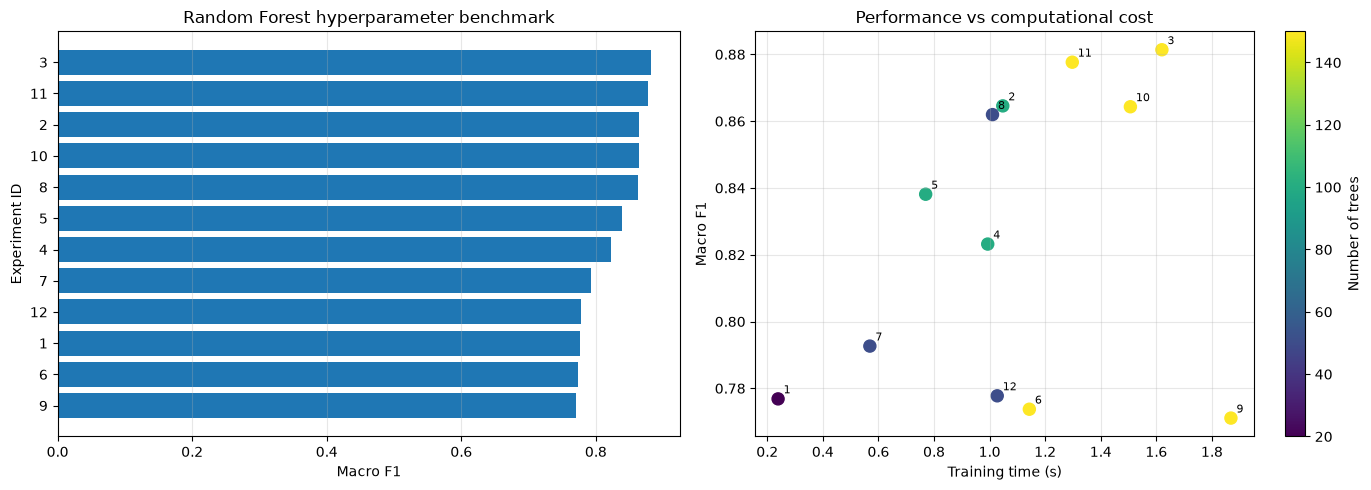

Top 5 configurations:


,experiment,n_estimators,max_depth,min_samples_leaf,max_features,alpha,accuracy,macro_f1,weighted_f1,train_time,predict_time
0,3,150,NaN,1,sqrt,0.50,0.9191,0.8814,0.9188,1.6199,0.2309
1,11,150,NaN,1,sqrt,0.75,0.9138,0.8777,0.9137,1.2975,0.2100
2,2,100,25.0,2,sqrt,0.50,0.8976,0.8646,0.8974,1.0474,0.1570
3,10,150,NaN,1,sqrt,0.00,0.9183,0.8643,0.9174,1.5066,0.2335
4,8,50,NaN,5,0.5,0.75,0.9033,0.8620,0.9039,1.0104,0.0816


In [3]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Macro F1 ranking
ranked = benchmark_df.sort_values("macro_f1")

axes[0].barh(
    ranked["experiment"].astype(str),
    ranked["macro_f1"]
)
axes[0].set_xlabel("Macro F1")
axes[0].set_ylabel("Experiment ID")
axes[0].set_title("Random Forest hyperparameter benchmark")
axes[0].grid(axis="x", alpha=0.3)

# Performance versus training time
scatter = axes[1].scatter(
    benchmark_df["train_time"],
    benchmark_df["macro_f1"],
    c=benchmark_df["n_estimators"],
    cmap="viridis",
    s=75
)

for _, row in benchmark_df.iterrows():
    axes[1].annotate(
        str(int(row["experiment"])),
        (row["train_time"], row["macro_f1"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

axes[1].set_xlabel("Training time (s)")
axes[1].set_ylabel("Macro F1")
axes[1].set_title("Performance vs computational cost")
axes[1].grid(alpha=0.3)

fig.colorbar(
    scatter, ax=axes[1],
    label="Number of trees"
)

plt.tight_layout()
plt.show()

print("Top 5 configurations:")
display(benchmark_df.head(5).round(4))


Training full model 3...
Training full model 11...
Training full model 2...


,experiment,accuracy,macro_f1,train_time
0,3,0.9527,0.9276,9.2618
1,11,0.9498,0.9264,7.7829
2,2,0.9290,0.9096,5.7264


Best model: {'n_estimators': 150, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'alpha': 0.5}
              precision    recall  f1-score   support

           1       0.96      0.94      0.95     31776
           2       0.95      0.97      0.96     42495
           3       0.93      0.96      0.95      5363
           4       0.91      0.86      0.88       412
           5       0.88      0.87      0.87      1424
           6       0.91      0.92      0.92      2605
           7       0.96      0.97      0.96      3077

    accuracy                           0.95     87152
   macro avg       0.93      0.93      0.93     87152
weighted avg       0.95      0.95      0.95     87152



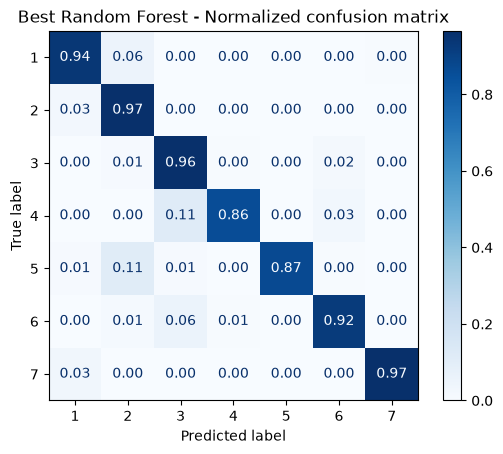

In [4]:

top_configs = benchmark_df.head(3)

final_results = []
trained_models = {}

for _, row in top_configs.iterrows():
    experiment_id = int(row["experiment"])
    params = configs[experiment_id - 1]

    print(f"Training full model {experiment_id}...", flush=True)

    model = RandomForestClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features=params["max_features"],
        class_weight=get_class_weights(params["alpha"]),
        random_state=42,
        n_jobs=-1
    )

    start = perf_counter()
    model.fit(X_train, y_train)
    train_time = perf_counter() - start

    predictions = model.predict(X_val)

    final_results.append({
        "experiment": experiment_id,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "train_time": train_time,
    })

    trained_models[experiment_id] = model

final_df = (
    pd.DataFrame(final_results)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(final_df.round(4))

best_id = int(final_df.iloc[0]["experiment"])
best_model = trained_models[best_id]

predictions = best_model.predict(X_val)

print("Best model:", configs[best_id - 1])
print(classification_report(y_val, predictions))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    predictions,
    normalize="true",
    cmap="Blues",
    values_format=".2f"
)

plt.title("Best Random Forest - Normalized confusion matrix")
plt.show()


Testing No PCA...
Testing Numeric PCA 95%...
Testing Global PCA 95%...


,preprocessing,accuracy,macro_f1,train_time
0,No PCA,0.9527,0.9276,9.3181
1,Numeric PCA 95%,0.9282,0.8888,10.9520
2,Global PCA 95%,0.9429,0.9082,27.8121


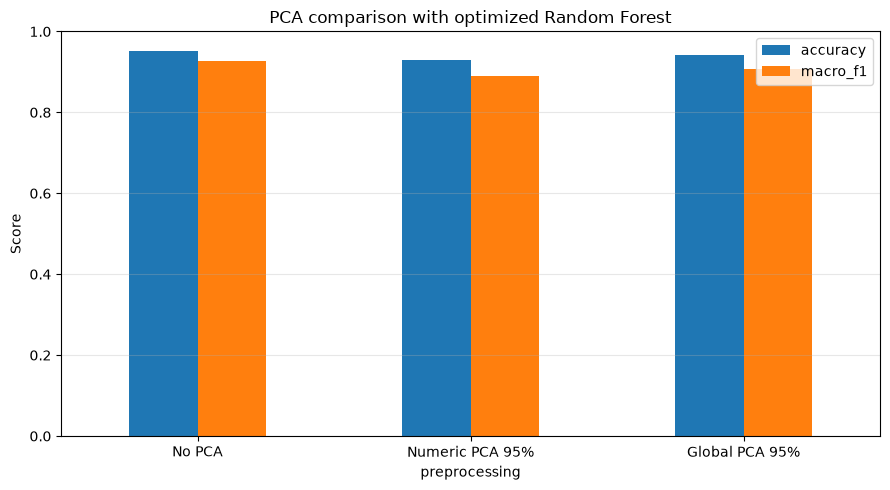

In [5]:

from sklearn.base import clone

preprocessing_configs = {
    "No PCA": PreprocessingConfig(
        scaling=False,
        pca="none"
    ),
    "Numeric PCA 95%": PreprocessingConfig(
        scaling=True,
        pca="numeric",
        pca_components=0.95
    ),
    "Global PCA 95%": PreprocessingConfig(
        scaling=True,
        pca="all",
        pca_components=0.95
    )
}

pca_results = []

for name, config in preprocessing_configs.items():
    print(f"Testing {name}...", flush=True)

    pipeline = Pipeline([
        ("preprocessing", build_preprocessor(config)),
        ("classifier", clone(best_model))
    ])

    start = perf_counter()
    pipeline.fit(X_train, y_train)
    train_time = perf_counter() - start

    predictions = pipeline.predict(X_val)

    pca_results.append({
        "preprocessing": name,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "train_time": train_time
    })

pca_df = pd.DataFrame(pca_results)

display(pca_df.round(4))

pca_df.plot(
    x="preprocessing",
    y=["accuracy", "macro_f1"],
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.ylabel("Score")
plt.title("PCA comparison with optimized Random Forest")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
